# 01 - Introducción a la regresión lineal

**Hecho por:** Joshua Sancho

**Correo:** [joshsan1408@gmail.com](mailto:joshsan1408@gmail.com)

**LinkedIn:** [joshsan1408](https://www.linkedin.com/in/joshsan1408/)

In [1]:
%matplotlib inline

from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

## 1. Comprensión del problema

Una fila representa una persona. Queremos predecir `charges`, el costo médico
registrado: es una **regresión** porque el resultado es un importe numérico.
Aprendemos a estimarlo con ejemplos de costos conocidos.

| Entrada de la fuente | Significado |
| --- | --- |
| `age` | Edad en años |
| `sex` | Sexo registrado |
| `bmi` | Índice de masa corporal (IMC) |
| `children` | Hijos o dependientes cubiertos |
| `smoker` | Condición de fumador |
| `region` | Región de residencia en EE. UU. |

Elegiremos por **MAE**: cuánto falla la predicción en promedio, sin importar el
signo. Se expresa en unidades de `charges`; menor es mejor.

## 2. Comprensión de los datos

### Cargar y revisar

Usamos Medical Cost Personal Datasets, versión 1.
Conservamos `source_data` sin modificar y trabajamos con una copia.
`head()` muestra las primeras cinco filas para reconocer las columnas y cómo es un registro.

In [4]:
dataset_path = Path(kagglehub.dataset_download("mirichoi0218/insurance/versions/1"))
source_data = pd.read_csv(dataset_path / "insurance.csv")
data = source_data.copy()
data.head().round(2)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.92
1,18,male,33.77,1,no,southeast,1725.55
2,28,male,33.00,3,no,southeast,4449.46
3,33,male,22.70,0,no,northwest,21984.47
4,32,male,28.88,0,no,northwest,3866.86


`shape` devuelve `(filas, columnas)`: cuántos ejemplos tenemos y cuántas variables trae cada uno.

In [5]:
print(f"Filas: {data.shape[0]}\nColumnas: {data.shape[1]}")

Filas: 1338
Columnas: 7


`info()` muestra el tipo de cada columna y cuántos valores están presentes. Buscamos tipos inesperados o datos incompletos.

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


`nunique()` cuenta valores distintos por columna. Nos permite reconocer que `sex` y `smoker` tienen dos valores y `region`, cuatro.

In [7]:
data.nunique()

age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64

`unique()` muestra cuáles son los valores distintos de cada columna no numérica. Revisamos sus etiquetas antes de convertirlas en booleanos o categorías.

In [8]:
for column in data.select_dtypes(exclude="number").columns:
    print(f"{column}: {data[column].unique().tolist()}")

sex: ['female', 'male']
smoker: ['yes', 'no']
region: ['southwest', 'southeast', 'northwest', 'northeast']


Las columnas numéricas ya tienen los tipos adecuados. Como `sex` y `smoker`
tienen dos valores, los expresamos como indicadores: `is_male` e `is_smoker`.
`True` equivale a 1 y `False` a 0; `is_male=False` representa `female` y
`is_smoker=False`, `no`. Dejamos `region` como categoría porque tiene cuatro grupos.

`isna().sum()` cuenta los valores ausentes por columna: un cero indica que está completa.

In [9]:
data["is_male"] = data["sex"] == "male"
data["is_smoker"] = data["smoker"] == "yes"
data = data.drop(columns=["sex", "smoker"])

data["region"] = data["region"].astype("category")

In [10]:
pd.DataFrame({"DType": data.dtypes, "Null": data.isna().sum()})

,DType,Null
age,int64,0
bmi,float64,0
children,int64,0
region,category,0
charges,float64,0
is_male,bool,0
is_smoker,bool,0


`duplicated().sum()` cuenta las filas que repiten todos sus valores respecto de una aparición anterior.

In [11]:
print(f"Duplicados exactos: {data.duplicated().sum()}")

Duplicados exactos: 1


No hay faltantes y hay un duplicado exacto. Retiramos la copia antes de dividir
para que no aparezca en entrenamiento y prueba. Conservamos los costos extremos.

In [12]:
data = data.drop_duplicates(keep="first").copy()
print(f"Filas sin duplicados: {data.shape[0]}\nColumnas: {data.shape[1]}")

Filas sin duplicados: 1337
Columnas: 7


### Separar entrenamiento y prueba

Después de retirar duplicados, `X` contiene las seis entradas transformadas y
`y` el costo. Seleccionamos los tipos desde `X` para excluir el objetivo `charges`
del preprocesamiento. Los booleanos se conservan como indicadores.

Reservamos 20 % para evaluar al final: así comprobamos qué ocurre con personas
que el modelo no vio al entrenar. Desde aquí, exploramos **solo entrenamiento**.
La semilla 42 permite repetir el reparto aleatorio.

In [13]:
target_col = "charges"
X = data.drop(columns=target_col)
y = data[target_col]

In [14]:
numeric_features = X.select_dtypes("number").columns.tolist()
categorical_features = X.select_dtypes("category").columns.tolist()
boolean_features = X.select_dtypes("bool").columns.tolist()

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, random_state=42,
)
train = X_train.join(y_train)
print(f"Entrenamiento: {len(X_train)} filas. Prueba: {len(X_test)} filas.")

Entrenamiento: 1069 filas. Prueba: 268 filas.


### ¿Cómo varían los costos?

`describe()` resume media, dispersión, rango y cuartiles de las variables numéricas.
La mediana (`50%`) deja la mitad de los casos a cada lado; la media es el promedio.
`.T` coloca las variables en filas y `round(2)` facilita leer la tabla.

In [16]:
train.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1069.0,39.20,14.00,18.00,27.00,39.00,51.00,64.00
bmi,1069.0,30.54,6.05,15.96,26.18,30.20,34.43,53.13
children,1069.0,1.08,1.19,0.00,0.00,1.00,2.00,5.00
charges,1069.0,13030.20,11706.53,1121.87,4747.05,9290.14,16450.89,62592.87


### Asimetría (`skewness`)

`skew() > 0` indica cola derecha; `skew() < 0`, cola izquierda. Un valor cercano a cero
indica poca asimetría según esta medida, pero no demuestra normalidad.

Para reducir la asimetría podemos probar:

| Transformación | Uso | Requisito |
| --- | --- | --- |
| `sqrt(x)` | Comprimir suavemente una cola derecha. | `x >= 0` |
| `log(x)` | Comprimir más una cola derecha muy extendida. | `x > 0`; con ceros y sin negativos, probar `log1p(x)`. |
| Yeo–Johnson | Aprender una potencia para cualquiera de las dos colas. | Admite valores positivos, cero y negativos. |
| Reflexión seguida de `sqrt(x)` o `log(x)` | Tratar una cola izquierda como distancia a un límite superior conocido. | `sqrt(c - x)` requiere `c >= x`; `log(c - x)`, `c > x`, también para datos futuros. |

La reflexión sola invierte el signo, pero conserva la magnitud de la asimetría.
Comparamos `abs(skew())` antes y después; no hay un umbral que determine qué
transformación elegir.

Para modelar, confirmamos su utilidad mediante validación y una métrica de error
en la escala original del objetivo.

Para evitar **data leakage**, ajustamos las transformaciones que aprenden
parámetros dentro del **pipeline**, usando solo el entrenamiento de cada fold.
**Nunca las ajustamos con todos los datos antes de dividirlos.**
Aquí conservamos `charges` sin transformar.

In [17]:
train.select_dtypes("number").skew().round(2)

age         0.07
bmi         0.32
children    0.95
charges     1.51
dtype: float64

El histograma agrupa costos en intervalos. La altura de cada barra indica cuántas personas hay en ese intervalo.

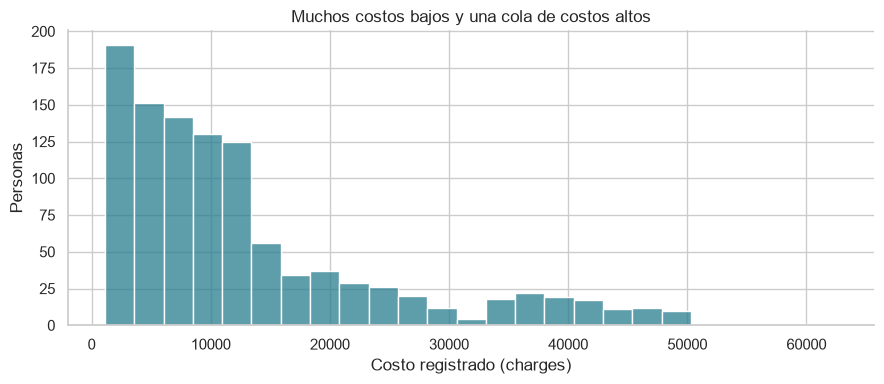

In [18]:
fig, ax = plt.subplots()
sns.histplot(data=train, x="charges", bins=25, color="#287c8e", ax=ax)
ax.set(xlabel="Costo registrado (charges)", ylabel="Personas",
       title="Muchos costos bajos y una cola de costos altos")
plt.tight_layout()
plt.show()

La asimetría de `charges` es **1,51**: respalda la cola derecha que muestra el histograma.
La media (13.030) supera la mediana (9.290) porque los costos altos elevan el promedio.
Elegimos **IQR** porque se basa en el 50 % central de los datos y es menos sensible
a los extremos que una regla basada en media y desviación estándar.

`Q1` es el percentil 25 y `Q3` el 75; `IQR = Q3 − Q1`. Señalamos valores fuera de
`[Q1 − 1.5 × IQR, Q3 + 1.5 × IQR]`. El factor 1,5 es una convención exploratoria,
no una frontera entre datos correctos e incorrectos. Conservamos esos casos.

**¿Cuándo usar dos desviaciones estándar?** Si la distribución fuera aproximadamente
normal, con forma de campana, tomar dos desviaciones por debajo y por encima de la
media cubriría cerca del 95 % de los casos. Aquí la cola derecha hace más apropiada la regla IQR.
Los límites se calculan solo con `y_train`.

In [19]:
q1, q3 = y_train.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = (y_train < lower) | (y_train > upper)

pd.Series({"Límite inferior": lower, "Límite superior": upper,
           "Casos señalados": outliers.sum(), "Porcentaje": outliers.mean() * 100}).round(2)

Límite inferior   -12808.71
Límite superior    34006.66
Casos señalados      106.00
Porcentaje             9.92
dtype: float64

### EDA: comparar grupos y relaciones

Usamos solo `train` y nos concentramos en fumadores, IMC, edad y región.
`size` cuenta casos; `mean` y `median` resumen costos. En las tablas de porcentajes,
cada fila suma 100 %; en las de medianas mostramos costos, sin normalizar.
Las diferencias son asociaciones de esta muestra, no efectos causales.

Definimos los rangos una sola vez. `right=False` incluye el límite inferior:
un IMC de 25 pertenece a `25–<30`. `age_groups` conserva también `bmi_group`
para poder cruzar ambos rangos. Estos grupos se usan solo en el EDA.

In [20]:
bmi_groups = train.assign(bmi_group=pd.cut(
    train["bmi"], bins=[0, 20, 25, 30, 35, float("inf")], right=False,
    labels=["<20", "20–<25", "25–<30", "30–<35", "35+"],
))

age_groups = bmi_groups.assign(age_group=pd.cut(
    train["age"], bins=[0, 30, 45, float("inf")], right=False,
    labels=["<30", "30–44", "45+"],
))

#### ¿Qué cambia entre fumadores y no fumadores?

`groupby("is_smoker")` separa no fumadores (`False`) y fumadores (`True`);
`agg()` calcula los resúmenes de cada grupo.

In [21]:
train.groupby("is_smoker")["charges"].agg(["size", "mean", "median"]).round(2)

,size,mean,median
is_smoker,,,
False,855,8498.48,7348.14
True,214,31135.93,33391.68


La mediana es 33.392 en fumadores y 7.348 en no fumadores.
¿Cambia la proporción de fumadores según el sexo? `unstack` coloca `False` y `True`
en columnas; cada fila muestra los porcentajes dentro de ese sexo.

In [22]:
train.groupby("is_male")["is_smoker"].value_counts(normalize=True).unstack("is_smoker").mul(100).round(2)

is_smoker,False,True
is_male,,
False,83.43,16.57
True,76.73,23.27


Son fumadores el 23,27 % de los hombres y el 16,57 % de las mujeres.
Ahora comparamos costos por sexo dentro de cada condición de fumador.

In [23]:
pd.crosstab(
    index=bmi_groups["is_male"],
    columns=[bmi_groups["is_smoker"]],
    values=bmi_groups["charges"],
    aggfunc="median"
).round(2)

is_smoker,False,True
is_male,,
False,7640.31,25902.23
True,6818.41,34817.56


En no fumadores, la mediana es mayor en mujeres; en fumadores, es mayor en
hombres. La comparación cambia al separar los grupos.

Revisamos también qué porcentaje fuma dentro de cada rango de IMC.

In [24]:
bmi_groups.groupby("bmi_group", observed=True)["is_smoker"].value_counts(normalize=True).unstack("is_smoker").mul(100).round(2)

is_smoker,False,True
bmi_group,,
<20,73.33,26.67
20–<25,77.51,22.49
25–<30,80.76,19.24
30–<35,81.49,18.51
35+,79.59,20.41


En los rangos desde IMC 25, fuma aproximadamente entre 19 % y 20 % de los casos.
Comparemos ahora los costos: una proporción parecida de fumadores no implica
medianas de costo parecidas.

In [25]:
pd.crosstab(
    index=bmi_groups["is_smoker"],
    columns=[bmi_groups["bmi_group"]],
    values=bmi_groups["charges"],
    aggfunc="median"
).T.round(2)

is_smoker,False,True
bmi_group,,
<20,4796.96,16298.50
20–<25,6402.29,19479.90
25–<30,6993.20,21348.71
30–<35,8116.27,38998.55
35+,8347.16,42385.78


En fumadores, la mediana pasa de 21.349 en `25–<30` a 38.999 en `30–<35`;
en no fumadores, de 6.993 a 8.116. La diferencia entre rangos es mucho mayor
en fumadores. Repetimos el cruce con el número de dependientes.

In [26]:
pd.crosstab(
    index=train["is_smoker"],
    columns=[train["children"]],
    values=train["charges"],
    aggfunc="median"
).T.round(2)

is_smoker,False,True
children,,
0,6185.32,32548.34
1,7050.64,31837.57
2,7371.77,36941.01
3,8571.82,27783.62
4,11033.66,30827.36
5,8596.83,19023.26


Las medianas son mayores en fumadores en cada nivel de dependientes.
En ninguno de los dos grupos aumentan de forma continua con el número
de dependientes.

Los cruces muestran diferencias grandes por condición de fumador, con variaciones
según sexo, IMC y dependientes. El gráfico resume la relación entre IMC y costos.

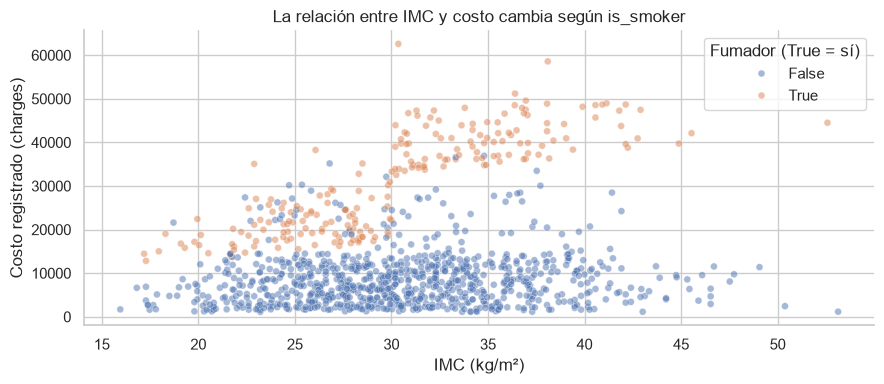

In [27]:
fig, ax = plt.subplots()
sns.scatterplot(data=train, x="bmi", y="charges", hue="is_smoker", alpha=0.5, s=25, ax=ax)
ax.set(xlabel="IMC (kg/m²)", ylabel="Costo registrado (charges)",
       title="La relación entre IMC y costo cambia según is_smoker")
ax.legend(title="Fumador (True = sí)")
plt.tight_layout()
plt.show()

Los puntos sugieren que la relación IMC–costo cambia según `is_smoker`.

#### ¿Quién tiene mayores costos: hombres o mujeres?

`is_male=False` corresponde a mujeres y `True`, a hombres según la fuente.
Comparamos ambas medidas de costo antes de concluir quién tiene valores mayores.

In [28]:
train.groupby("is_male")["charges"].agg(["size", "mean", "median"]).round(2)

,size,mean,median
is_male,,,
False,519,12305.47,9411.00
True,550,13714.09,9289.08


La media es mayor en hombres (13.714 frente a 12.305), pero la mediana es ligeramente
menor (9.289 frente a 9.411). Arriba vimos además que tienen mayor proporción de
fumadores: estas diferencias no aíslan una asociación atribuible solo al sexo.

#### ¿Qué cambia entre rangos de IMC?

Usamos los grupos definidos al inicio para resumir los costos y comparar luego
con sexo y edad. La mediana ayuda a que los costos extremos no dominen la lectura.

In [29]:
bmi_groups.groupby("bmi_group", observed=True)["charges"].agg(
    Cantidad="size", Media="mean", Mediana="median",
).round(2)

,Cantidad,Media,Mediana
bmi_group,,,
<20,30,8386.75,6696.79
20–<25,169,10712.96,8891.14
25–<30,317,10893.10,8615.30
30–<35,308,14478.13,9723.65
35+,245,16142.12,10381.48


La media pasa de 8.387 en IMC menor de 20 a 16.142 en IMC de 35 o más.
Las medianas cambian menos y no crecen en cada intervalo. El primer grupo tiene
30 casos. El cruce con fumadores ya mostrado indica que la diferencia entre
`25–<30` y `30–<35` es mucho mayor en fumadores que en no fumadores.

Revisamos ahora las medianas por sexo dentro de cada rango.

In [30]:
bmi_groups.pivot_table(
    index="bmi_group", columns="is_male", values="charges",
    aggfunc="median", observed=True,
).round(2)

is_male,False,True
bmi_group,,
<20,6877.98,5855.90
20–<25,9115.30,8605.36
25–<30,8930.93,8525.35
30–<35,9888.33,9676.58
35+,9704.67,11172.63


Al separar por sexo, las mujeres tienen una mediana algo mayor en los primeros
cuatro rangos, pero en `35+` es mayor en hombres. No hay una diferencia uniforme.

#### ¿Cómo cambian los costos con la edad?

Usamos los tres grupos definidos al inicio para resumir la tendencia y después
comparar dentro de cada condición de fumador y rango de IMC.

In [31]:
age_groups.groupby("age_group", observed=True)["charges"].agg(
    Cantidad="size", Media="mean", Mediana="median",
).round(2)

,Cantidad,Media,Mediana
age_group,,,
<30,334,9640.77,3253.64
30–44,312,11323.16,6665.46
45+,423,16965.59,11946.63


Las medianas suben de 3.254 a 6.665 y 11.947 entre los tres grupos.
¿La tendencia se mantiene al separar fumadores y no fumadores?

In [32]:
pd.crosstab(
    index=age_groups["age_group"], columns=age_groups["is_smoker"],
    values=age_groups["charges"], aggfunc="median",
).round(2)

is_smoker,False,True
age_group,,
<30,2709.11,33732.69
30–44,6238.30,21774.32
45+,11345.52,40847.36


En no fumadores, las medianas aumentan con la edad: 2.709, 6.238 y 11.346.
En fumadores no aumentan de forma continua: el grupo intermedio tiene una mediana
menor. Crucemos edad con IMC para ver otra parte de la relación.

In [33]:
pd.crosstab(
    index=age_groups["age_group"], columns=age_groups["bmi_group"],
    values=age_groups["charges"], aggfunc="median",
).T.round(2)

age_group,<30,30–44,45+
bmi_group,,,
<20,3378.91,6905.61,8627.54
20–<25,2974.13,7986.48,12475.35
25–<30,3175.34,6555.07,11861.90
30–<35,3949.83,6571.02,11938.26
35+,3219.84,6435.62,12255.02


Dentro de cada rango de IMC, la mediana aumenta entre los grupos de edad.
Por ejemplo, en `25–<30` pasa de 3.175 a 6.555 y 11.862. La asociación con edad
se observa también al comparar personas del mismo rango de IMC.

#### ¿Más dependientes implica mayor costo?

`children` tiene solo seis valores, de 0 a 5: podemos compararlos directamente,
sin crear intervalos adicionales.

In [34]:
train.groupby("children")["charges"].agg(
    Cantidad="size", Media="mean", Mediana="median",
).round(2)

,Cantidad,Media,Mediana
children,,,
0,458,11975.55,9856.95
1,265,12419.66,8342.91
2,191,15212.64,9225.26
3,122,15033.59,10651.60
4,19,14915.32,11299.34
5,14,9298.06,8781.31


Las medias y medianas no aumentan de forma continua con `children`.
Los grupos de 4 y 5 dependientes tienen solo 19 y 14 casos. Esta tabla no respalda
una regla simple de «más dependientes, mayor costo» para todos los niveles.

#### ¿Hay diferencias entre regiones?

Comparamos los cuatro grupos registrados. Ordenamos por la media para facilitar
la lectura, pero también miramos la mediana.

In [35]:
train.groupby("region", observed=True)["charges"].agg(
    Cantidad="size", Media="mean", Mediana="median",
).sort_values("Media", ascending=False).round(2)

,Cantidad,Media,Mediana
region,,,
southeast,287,14554.66,9058.73
northeast,253,13241.15,9875.68
southwest,265,12296.42,8968.33
northwest,264,11907.34,8749.24


`southeast` tiene la media mayor (14.555), pero la mediana mayor está en
`northeast` (9.876). Revisamos primero la proporción de fumadores de cada región.

In [36]:
pd.crosstab(
    train["region"], train["is_smoker"], normalize="index",
).mul(100).round(1)

is_smoker,False,True
region,,
northeast,79.1,20.9
northwest,83.7,16.3
southeast,74.9,25.1
southwest,82.6,17.4


Hay 25,1 % de fumadores en `southeast` y 16,3 % en `northwest`.
La composición regional es distinta. Comparamos costos dentro de cada condición
de fumador y, después, dentro de cada rango de IMC.

In [37]:
pd.crosstab(
    index=train["region"], columns=train["is_smoker"],
    values=train["charges"], aggfunc="median",
).round(2)

is_smoker,False,True
region,,
northeast,8334.52,24873.38
northwest,7153.55,24535.70
southeast,6500.24,36228.64
southwest,7512.27,34833.76


Entre fumadores, la mediana va de 24.536 en `northwest` a 36.229 en `southeast`.
Entre no fumadores, `southeast` tiene la menor mediana (6.500). El orden regional
cambia al separar por fumador. ¿Qué ocurre al separar por IMC?

In [38]:
pd.crosstab(
    index=bmi_groups["region"], columns=bmi_groups["bmi_group"],
    values=bmi_groups["charges"], aggfunc="median",
).round(2)

bmi_group,<20,20–<25,25–<30,30–<35,35+
region,,,,,
northeast,7005.94,9500.57,9158.74,11488.32,12890.06
northwest,5486.20,8017.06,9118.83,9379.01,8733.23
southeast,17179.52,10434.42,8442.67,9006.05,9549.57
southwest,3378.91,6250.44,8742.96,9414.92,10387.88


Dentro del rango de IMC `35+`, la mediana del costo es mayor en
`northeast` (12.890) que en `southeast` (9.550). La comparación corresponde
a personas del mismo rango de IMC, pero no separa por edad ni por
condición de fumador.

#### Pearson y Spearman: ¿recta o tendencia de orden?

| Correlación | Qué compara | Qué relación resume |
| --- | --- | --- |
| Pearson | Los valores originales. | Lineal: qué tan bien siguen una recta. |
| Spearman | Sus rangos: posiciones de menor a mayor. | Monótona: al crecer una variable, la otra tiende a subir o a bajar, aunque forme una curva. |

Ambas van de −1 a 1: el signo indica dirección y la magnitud, intensidad de esa
asociación. Spearman puede captar una curva creciente como `y = x²` con `x >= 0`;
no detecta cualquier relación no lineal. Una forma de U puede dar correlaciones
cercanas a cero en ambas medidas.

Comparamos los tres predictores numéricos con `charges`. Las categorías ya se
examinaron como grupos, sin asignar un orden artificial a las regiones.

In [39]:
numeric_data = train[numeric_features + [target_col]]
correlations = pd.DataFrame({
    "Pearson": numeric_data.corr(method="pearson")[target_col],
    "Spearman": numeric_data.corr(method="spearman")[target_col],
}).drop(index=target_col)
correlations.round(2)

,Pearson,Spearman
age,0.29,0.52
bmi,0.18,0.11
children,0.09,0.14


En edad, Spearman es 0,52 y Pearson 0,29: la asociación por orden es más marcada
que la lineal. La diferencia puede reflejar la forma de la relación, los extremos
o la mezcla de grupos; por sí sola no demuestra curvatura.

En IMC, Pearson es 0,18 y Spearman 0,11: ambos resúmenes globales son bajos,
aunque las tablas por fumador muestran diferencias importantes. `children` también
tiene asociaciones bajas (0,09 y 0,14), coherentes con una tendencia poco uniforme.
Una correlación baja no basta para descartar una entrada ni demuestra ausencia de relación.

#### ¿Los predictores numéricos repiten información?

Revisamos ahora correlaciones **entre entradas**, sin incluir el objetivo.
Una redundancia fuerte puede volver inestables sus coeficientes: es la
multicolinealidad. Aquí usamos Pearson para revisar redundancia lineal.

In [40]:
train[numeric_features].corr(method="pearson").round(2)

,age,bmi,children
age,1.00,0.12,0.06
bmi,0.12,1.00,0.00
children,0.06,0.00,1.00


La mayor correlación absoluta entre estas entradas es 0,12: no observamos
redundancia lineal fuerte entre edad, IMC y dependientes.

#### ¿Qué nos llevamos al modelado?

- Los costos de fumadores y no fumadores difieren mucho; el IMC muestra cambios mayores en fumadores.
- La mediana aumenta con la edad dentro de cada rango de IMC.
- Las diferencias regionales cambian al separar por fumador o IMC; sus promedios no son efectos aislados.
- Sexo y dependientes aportan contexto, sin una diferencia uniforme en todos los grupos.

Conservamos las seis entradas. Los rangos son solo para explorar y no cambian
`X_train`, la cuadrícula ni el modelo.

## 3. Preparación de los datos

`ColumnTransformer` aplica una preparación distinta a cada tipo de entrada.

### Categorías: OneHotEncoder u OrdinalEncoder

| Codificador | Qué produce | Cuándo usarlo |
| --- | --- | --- |
| OneHotEncoder | Indicadores 0/1 por categoría. | Categorías sin orden natural, como las regiones. |
| OrdinalEncoder | Una columna de códigos, por ejemplo bajo = 0, medio = 1, alto = 2. | Categorías con un orden conocido, que especificamos mediante `categories`. |

En una regresión, usar 0, 1 y 2 supone el mismo cambio de predicción entre niveles
consecutivos. Si ese supuesto no es adecuado, podemos usar OneHotEncoder incluso
cuando exista un orden.

Aquí usamos **OneHotEncoder para `region`**, porque no hay un orden entre regiones.
`drop="first"` omite una referencia y evita redundancia con el intercepto.

### Numéricos: ¿qué escalador elegir?

| Escalador | Qué hace por defecto | Cuándo probarlo |
| --- | --- | --- |
| StandardScaler | Resta la media y divide por la desviación estándar. | Entradas con unidades distintas, especialmente al usar regularización como Ridge o Lasso. Es sensible a extremos. |
| MinMaxScaler | Usa mínimo y máximo para llevar el rango de entrenamiento a `[0, 1]`. | Cuando interesa un intervalo común. Los extremos pueden comprimir mucho al resto de valores. |
| RobustScaler | Resta la mediana y divide por el IQR. | Cuando los extremos de las entradas distorsionan la media y la desviación estándar. |

Escalar no elimina atípicos ni corrige la asimetría. Además, MinMaxScaler puede
producir valores fuera de `[0, 1]` en datos nuevos.

Aquí usamos **StandardScaler para edad, IMC y dependientes**: los expresamos en
una escala comparable para la penalización de Ridge y Lasso.

### ¿Qué hace `passthrough`?

Passthrough
conserva las columnas sin transformarlas. Se usa cuando ya tienen una representación
adecuada para el modelo. Aquí mantiene **`is_male` e `is_smoker` como indicadores
0/1**, sin escalarlos ni volver a codificarlos.

No necesitamos imputar porque no hay nulos. El pipeline aprenderá las categorías
y las estadísticas de escalado solo con el entrenamiento de cada fold.

In [41]:
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("boolean", "passthrough", boolean_features),
    ("categorical", OneHotEncoder(drop="first", handle_unknown="error",
                                  sparse_output=False), categorical_features),
])

El **pipeline** une preparación y regresión: `fit` aprende ambos pasos y `predict` reutiliza lo aprendido para nuevas filas.

In [42]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression()),
])

## 4. Modelado

### Predecir: sumar aportes

Los tres modelos usan la misma forma sobre las entradas **ya transformadas**:

$$\hat y = \beta_0 + \beta_1 x_1 + \cdots + \beta_p x_p.$$

$\hat y$ es el costo estimado; $\beta_0$, el nivel base o **intercepto**.
Cada coeficiente $\beta_j$ multiplica una entrada $x_j$; $p$ es el número de entradas transformadas.

**Ejemplo ficticio con solo dos entradas:** nivel base 8.000, aporte de edad
3.500 por desviación estándar y aporte de fumador 23.000. Para alguien una
desviación por encima de la edad media y no fumador:

$$\hat y = 8\,000 + 3\,500 \times 1 + 23\,000 \times 0 = 11\,500.$$

Al entrenar, el modelo aprende el intercepto y los coeficientes. Cambia el criterio
que usa cada regresor para elegirlos.

### Entrenar: error y penalización

Llamemos $S$ a la **suma de errores cuadrados**:

$$
S = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

$y_i$ es el valor real de la observación $i$; $\hat{y}_i$, su predicción;
$n$ es la cantidad de observaciones de entrenamiento. Restamos, elevamos al
cuadrado y sumamos para todas las observaciones.

Si dos errores fueran 2 y −3, su aporte sería $S = 2^2 + (-3)^2 = 13$:
no se cancelan y el mayor pesa más.

| Modelo | Cantidad que minimiza | Idea |
| --- | --- | --- |
| Regresión lineal | $S$ | Busca reducir el error cuadrático. |
| Ridge | $S + \alpha\sum_j\beta_j^2$ | Penaliza coeficientes grandes con sus cuadrados (L2). |
| Lasso | $S/(2n) + \alpha\sum_j\lvert\beta_j\rvert$ | Penaliza valores absolutos (L1); puede llevar coeficientes a cero. |

$\sum$ significa sumar y $n$ es la cantidad de filas usadas al entrenar.
Con coeficientes ficticios 2 y −1, la parte L2 suma $4+1=5$ y la L1 suma $2+1=3$,
antes de multiplicar por `alpha`.

Un `alpha` mayor da más peso a la penalización. El intercepto no se penaliza.
Estas son las convenciones de scikit-learn: Lasso divide $S$ por $2n$ y Ridge no;
por eso sus valores de `alpha` no son equivalentes. **Los modelos se ajustan con
estas funciones; MAE selecciona entre sus resultados.**

### Baseline

Como referencia independiente, predecimos siempre la mediana de entrenamiento.
Es la constante que minimiza el error absoluto. Superarla indica que las entradas
aportan utilidad frente a repetir un único costo para todos.

In [43]:
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)
print(f"El baseline predice siempre {baseline.constant_.item():,.2f}.")

El baseline predice siempre 9,290.14.


### Comparar con validación cruzada

Probamos 11 configuraciones en las mismas cinco particiones (**folds**) de
entrenamiento. En cada ronda, cuatro partes entrenan y una valida: 55 ajustes.
Así la comparación depende menos de un único reparto de validación.
La prueba sigue reservada. `model__alpha` cambia `alpha` del paso `model`.

In [44]:
param_grid = [
    {"model": [LinearRegression()]},
    {"model": [Ridge()], "model__alpha": [0.01, 0.1, 1, 10, 100]},
    {"model": [Lasso(max_iter=10000)], "model__alpha": [0.01, 0.1, 1, 10, 100]},
]
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [45]:
grid = GridSearchCV(
    pipeline, param_grid=param_grid, cv=cv,
    scoring="neg_mean_absolute_error", n_jobs=-1,
    refit=True, error_score="raise",
)
grid.fit(X_train, y_train);

Scikit-learn maximiza la puntuación: usamos MAE negativo y recuperamos su signo
positivo al mostrarlo. La desviación indica variabilidad entre folds, no un
intervalo de confianza.

In [46]:
parameters = grid.cv_results_["params"]
cv_summary = pd.DataFrame({
    "Modelo": [type(p["model"]).__name__ for p in parameters],
    "alpha": [p.get("model__alpha", "—") for p in parameters],
    "MAE validación": -grid.cv_results_["mean_test_score"],
    "Desviación": grid.cv_results_["std_test_score"],
}).sort_values("MAE validación")
cv_summary.round(2)

,Modelo,alpha,MAE validación,Desviación
9,Lasso,10,4220.49,207.02
8,Lasso,1,4221.79,208.41
7,Lasso,0.1,4221.95,208.53
6,Lasso,0.01,4221.96,208.55
0,LinearRegression,—,4221.96,208.55
1,Ridge,0.01,4222.06,208.52
2,Ridge,0.1,4222.98,208.27
10,Lasso,100,4230.53,193.48
3,Ridge,1,4232.15,205.78
4,Ridge,10,4328.13,187.18


Lasso con `alpha=10` obtiene el menor MAE: **4.220,49**. Su ventaja sobre la
regresión lineal es pequeña (aproximadamente 1,47). La búsqueda conserva ese
ganador y, con `refit=True`, lo reajusta automáticamente con todo entrenamiento.

In [47]:
best_model = grid.best_estimator_
best_params = grid.best_params_
best_cv_mae = -grid.best_score_

print("Mejor configuración:", best_params)
print(f"MAE de validación: {best_cv_mae:,.2f}")

Mejor configuración: {'model': Lasso(max_iter=10000), 'model__alpha': 10}
MAE de validación: 4,220.49


### Interpretar el ganador

Los coeficientes numéricos expresan el cambio por una desviación estándar.
Los booleanos indican el cambio de `False` a `True`; los de región, la diferencia
frente a la región de referencia. En todos los casos, mantenemos lo demás fijo.
Consultamos el modelo ya ajustado y la referencia aprendida para `region`.

In [48]:
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_model = best_model.named_steps["model"]
encoder = fitted_preprocessor.named_transformers_["categorical"]

pd.Series({column: categories[0] for column, categories in
           zip(categorical_features, encoder.categories_)}, name="Referencia")

region    northeast
Name: Referencia, dtype: str

In [49]:
coefficients = pd.Series(
    fitted_model.coef_, index=fitted_preprocessor.get_feature_names_out(),
    name="Coeficiente",
)
print(f"Intercepto: {fitted_model.intercept_:,.2f}")
coefficients.round(2)

Intercepto: 8,803.42


numeric__age                      3466.54
numeric__bmi                      1904.21
numeric__children                  627.83
boolean__is_male                   -54.17
boolean__is_smoker               23010.01
categorical__region_northwest     -224.32
categorical__region_southeast     -654.46
categorical__region_southwest     -486.29
Name: Coeficiente, dtype: float64

En el ganador, `is_smoker=True` aporta unas 23.010 unidades frente a `False`.
Una desviación estándar adicional de edad aporta unas 3.467. Lasso penaliza
coeficientes, pero aquí no dejó ninguno en cero. Estos ajustes no son efectos causales.

## 5. Evaluación

La elección terminó. Predecimos las mismas filas reservadas con el ganador y
el baseline, sin volver a ajustar.

### MAE, MSE y RMSE: ¿qué mide cada uno?

Aquí $S$ es la suma de errores cuadrados y $n$, la cantidad de observaciones evaluadas.

| Métrica | Cálculo | Unidades |
| --- | --- | --- |
| MAE | Promedio de errores absolutos. | Las del objetivo. |
| MSE | Promedio de errores cuadrados: $S/n$. | Las del objetivo al cuadrado. |
| RMSE | Raíz del MSE: $\sqrt{MSE}$. | Las del objetivo. |

Con errores ficticios de 2 y −3: **MAE = 2,50**, **MSE = 6,50** y **RMSE ≈ 2,55**.
MSE y RMSE dan más peso a los errores grandes; sus valores no se comparan
numéricamente entre sí porque MSE tiene otras unidades.

### ¿Por qué seleccionamos por MAE?

En esta sesión priorizamos **cuánto falla la predicción en promedio**, en las
unidades del objetivo. MAE pondera los errores proporcionalmente y es menos
sensible a errores extremos que MSE y RMSE, algo útil en esta distribución con cola derecha.

Elegiríamos MSE o RMSE como criterio si quisiéramos dar más peso a errores grandes;
RMSE facilita interpretar el resultado en las unidades originales. Aquí **sí los
calculamos para evaluar**, pero **no los usamos para elegir al ganador**. La selección
permanece basada en el MAE de validación.

### ¿Qué nos dice R²?

**R² indica qué proporción de la variabilidad de la variable objetivo explica el
modelo usando sus entradas**, tomando como referencia predecir siempre la media
del conjunto evaluado.

Por ejemplo, si un modelo obtiene **R² = 0,81**, explica aproximadamente el **81 %
de esa variabilidad**. Se refiere al modelo completo, no al aporte de cada variable
por separado, y no demuestra causalidad.

- **R² = 1:** predicciones perfectas.
- **R² = 0:** el mismo error cuadrático que predecir siempre esa media.
- **R² < 0:** mayor error cuadrático que esa referencia.

Un valor mayor es mejor. **No es un porcentaje de predicciones correctas.**
La referencia de R² usa la media del conjunto evaluado; nuestro baseline
independiente usa la mediana aprendida en entrenamiento.

In [50]:
y_pred = best_model.predict(X_test)
baseline_pred = baseline.predict(X_test)

In [51]:
metrics = pd.DataFrame({
    "MAE": [mean_absolute_error(y_test, y_pred), mean_absolute_error(y_test, baseline_pred)],
    "MSE": [mean_squared_error(y_test, y_pred), mean_squared_error(y_test, baseline_pred)],
    "RMSE": [root_mean_squared_error(y_test, y_pred), root_mean_squared_error(y_test, baseline_pred)],
    "R²": [r2_score(y_test, y_pred), r2_score(y_test, baseline_pred)],
}, index=[type(fitted_model).__name__, "Baseline: mediana"])
metrics.style.format("{:,.2f}")

,MAE,MSE,RMSE,R²
Lasso,"4,184.38","35,636,323.73","5,969.62",0.81
Baseline: mediana,"9,293.84","208,575,073.40","14,442.13",-0.14


El MAE final es **4.184,38**, frente a **9.293,84** del baseline. Es una mejora en
esta prueba; el promedio no dice cuánto falla cada persona.

### ¿Dónde se equivoca?

**Residuo = real − predicho**: positivo significa subestimación; negativo,
sobreestimación. Conservamos el índice para relacionar cada error con sus entradas.

In [52]:
errors = X_test.copy()
errors["actual"] = y_test
errors["prediction"] = y_pred
errors["residual"] = errors["actual"] - errors["prediction"]
errors["absolute_error"] = errors["residual"].abs()

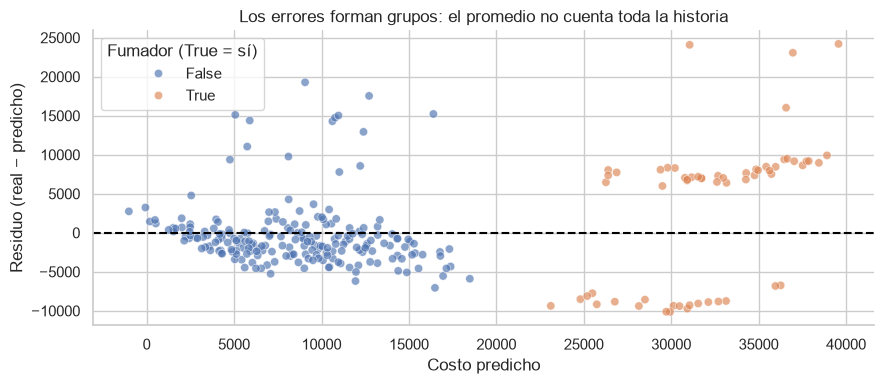

In [53]:
fig, ax = plt.subplots()
sns.scatterplot(data=errors, x="prediction", y="residual", hue="is_smoker", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linestyle="--")
ax.set(xlabel="Costo predicho", ylabel="Residuo (real − predicho)",
       title="Los errores forman grupos: el promedio no cuenta toda la historia")
ax.legend(title="Fumador (True = sí)")
plt.tight_layout()
plt.show()

Los residuos forman bandas y su dispersión cambia: quedan patrones sin explicar.
El MAE por `is_smoker` cuantifica la magnitud del error; el residuo medio indica
en qué dirección falla cada grupo. Un residuo medio cercano a cero puede ocultar
errores grandes de signos opuestos que se cancelan.

In [54]:
errors.groupby("is_smoker", observed=True).agg(
    Cantidad=("absolute_error", "size"),
    MAE=("absolute_error", "mean"),
    Residuo_medio=("residual", "mean"),
).round(2)

,Cantidad,MAE,Residuo_medio
is_smoker,,,
False,208,2772.3,-357.39
True,60,9079.6,3188.86


El MAE es 9.079,60 en fumadores y 2.772,30 en no fumadores. En promedio,
subestima al primer grupo y sobreestima al segundo. Veamos los cinco errores mayores.

In [55]:
errors.nlargest(5, "absolute_error")[[
    "age", "bmi", "is_smoker", "actual", "prediction", "residual",
]].round(2)

,age,bmi,is_smoker,actual,prediction,residual
543,54,47.41,True,63770.43,39566.58,24203.85
819,33,35.53,True,55135.40,31054.16,24081.24
1230,52,34.48,True,60021.40,36955.54,23065.86
987,45,27.64,False,28340.19,9060.73,19279.45
115,60,28.60,False,30260.00,12720.46,17539.54


Los cinco casos son subestimaciones grandes. También hay dos predicciones
negativas: la regresión no garantiza costos no negativos. Las conservamos;
no cambiamos el modelo a partir de esta evaluación.

In [56]:
errors.loc[errors["prediction"] < 0, ["actual", "prediction"]].round(2)

,actual,prediction
428,3167.46,-70.21
1129,1728.90,-1015.84


## 6. Uso de los resultados

Creamos una persona **ficticia** con las mismas seis entradas de `X`.
Usamos `is_male=False` e `is_smoker=False` para representar una mujer no fumadora.
`predict` aplica automáticamente el escalado, la codificación de región y el modelo ganador.

In [57]:
new_observation = pd.DataFrame([{
    "age": 35, "bmi": 27.5, "children": 1, "region": "northeast",
    "is_male": False, "is_smoker": False,
}])
prediction = best_model.predict(new_observation)[0]
print(f"Costo estimado para el ejemplo ficticio: {prediction:,.2f}")

Costo estimado para el ejemplo ficticio: 6,761.90


Lasso (`alpha=10`) fue elegido por validación y superó al baseline en la prueba.
El pipeline está listo para recibir las mismas seis entradas y categorías conocidas.

El error es mayor en fumadores y hay subestimaciones grandes. Estudiar una
interacción IMC–fumador sería una hipótesis para otro ciclo, con datos nuevos.
Esta muestra no garantiza representatividad y sus asociaciones no demuestran causas.

## Referencias

Documentación oficial para consultar los conceptos y las herramientas de la sesión.

### Datos y exploración con pandas

- [Medical Cost Personal Datasets, versión 1](https://www.kaggle.com/datasets/mirichoi0218/insurance/versions/1): fuente de los datos.
- [KaggleHub: descarga de datasets](https://github.com/Kaggle/kagglehub#download-datasets).
- [Primeros pasos con pandas](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html): cargar, seleccionar y explorar datos.
- [Estadística descriptiva: describe](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html) y [asimetría: skew](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.skew.html).
- [Agrupaciones y agregaciones: groupby](https://pandas.pydata.org/docs/user_guide/groupby.html).
- [Tablas cruzadas: crosstab](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html), [rangos: cut](https://pandas.pydata.org/docs/reference/api/pandas.cut.html) y [pasar niveles del índice a columnas: unstack](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.unstack.html).
- [Rango intercuartílico: IQR](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.iqr.html).
- [Correlación de Pearson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) y [correlación de Spearman](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html).

### Preparación y transformaciones

- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) y [OrdinalEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html): codificación de categorías.
- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html) y [RobustScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.RobustScaler.html): escalado de entradas.
- [ColumnTransformer y passthrough](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html): preparación por columnas.
- [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html): encadenar preparación y modelo.
- [Transformaciones de potencia y Yeo–Johnson](https://scikit-learn.org/stable/modules/preprocessing.html#mapping-to-a-gaussian-distribution).
- [Reflexión y asimetría](https://support.sas.com/documentation/cdl/en/stsug/62259/HTML/default/ugvartransform_sect15.htm).
- [Transformaciones de la variable objetivo](https://scikit-learn.org/stable/modules/compose.html#transforming-target-in-regression).
- [Fuga de información: data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

### Modelado y validación

- [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html), [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) y [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html): estimadores y funciones de ajuste.
- [DummyRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html): baseline constante.
- [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html): separar entrenamiento y prueba.
- [KFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html): particiones de validación cruzada.
- [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html): búsqueda, selección y reajuste del ganador.

### Métricas de evaluación

- [MAE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html): error absoluto medio.
- [MSE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html): error cuadrático medio.
- [RMSE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html): raíz del error cuadrático medio.
- [R²](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html): coeficiente de determinación.